In [132]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report)




In [133]:
# load the dataset

df = pd.read_csv("churn_dataset.csv")
df
print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [134]:
#data cleaning

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors="coerce")  #TotalCharges is stored as object/string in many versions

df.dropna(inplace=True)                 # Remove rows where TotalCharges could not be converted

df.drop("customerID",axis=1, inplace=True)       # CustomerID is not useful for prediction       

In [135]:
#Convert the target variable

#churn:yes=1, no=0
df["Churn"] = df["Churn"].map({
    "Yes":1,
    "No": 0
})

In [136]:
#Separate features and target

X = df.drop("Churn", axis=1)
y = df["Churn"]

In [137]:
X=pd.get_dummies(X, drop_first=True)

print("no. of features:", X.shape[1])

no. of features: 30


In [138]:
#train-test-split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.50,random_state=42,stratify=y)

print("Training data shape:",X_train.shape)
print("Testing data shape",X_test.shape)

Training data shape: (3516, 30)
Testing data shape (3516, 30)


In [139]:
#feature scaling

scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

In [140]:
#Train Logistic Regression model

model = LogisticRegression(max_iter=1000, random_state=42)

model.fit(X_train_scaled,y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [141]:
#Make predictions

y_pred = model.predict(X_test_scaled)


y_prob = model.predict_proba(X_test_scaled)[:,1]

In [142]:
#confusion matrix

cm = confusion_matrix(y_test, y_pred)

print("confusion_matrix",cm)

confusion_matrix [[2281  301]
 [ 394  540]]


In [ ]:
#evaluation metrics

accuracy = accuracy_score(y_test,y_pred)

precision = precision_score(y_test,y_pred)

recall = recall_score(y_test,y_pred)

f1 = f1_score(y_test,y_pred)


print("model evaluation")

print(f"Accuracy:{accuracy:.4f}")

print(f"Recall:{recall:.4}")

print(f"Precision:{precision:.4f}")

print(f"f1 score:{f1:.4f}")

model evaluation
Accuracy:0.8023
Precision:0.6421
f1 score:0.6085


In [144]:
#classification report

print(classification_report(y_test,y_pred,target_names=["No Churn","Churn"]))

              precision    recall  f1-score   support

    No Churn       0.85      0.88      0.87      2582
       Churn       0.64      0.58      0.61       934

    accuracy                           0.80      3516
   macro avg       0.75      0.73      0.74      3516
weighted avg       0.80      0.80      0.80      3516



In [145]:
#Roc curve and AUC

from sklearn.metrics import(roc_curve,roc_auc_score,precision_recall_curve,auc)

fpr,tpr, thresholds = roc_curve(y_test,y_prob)              #fpr:false positive rate. tpr:true positive rate

roc_auc = roc_auc_score(y_test, y_prob)

print(f"ROC_AUC:{roc_auc:.4f}")

ROC_AUC:0.8419


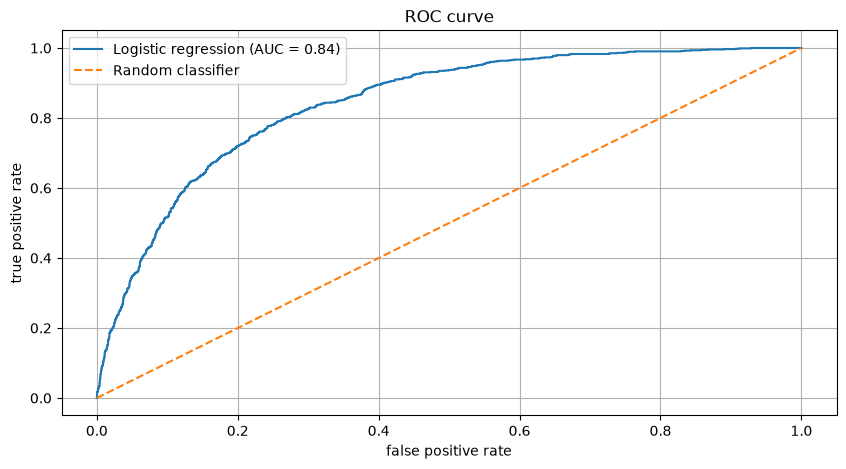

In [146]:
#plot ROC curve

plt.figure(figsize=(10,5))

plt.plot(fpr,tpr,label=f"Logistic regression (AUC = {roc_auc:.2f})")

plt.plot([0,1],[0,1],linestyle="--",label="Random classifier")

plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.title("ROC curve")
plt.legend()
plt.grid()
plt.show()

In [147]:
precision_values, recall_values, pr_thresholda = precision_recall_curve(y_test,y_prob)

pr_auc = auc(recall_values, precision_values)

print(f"PR-AUC:{pr_auc:.4f}")

PR-AUC:0.6397


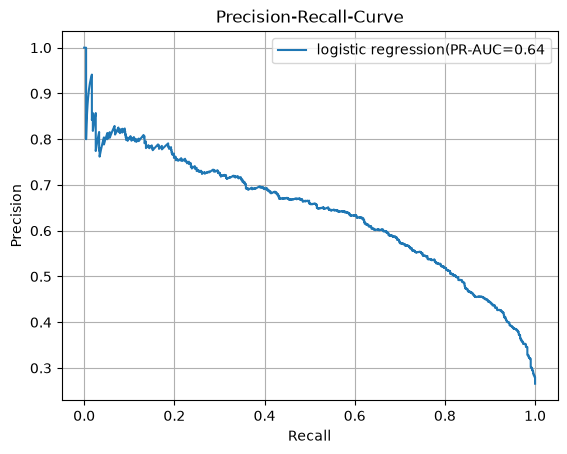

In [148]:
#PR curve

plt.Figure(figsize=(10,5))

plt.plot(recall_values,precision_values,label=f"logistic regression(PR-AUC={pr_auc:.2f}")


plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall-Curve")
plt.legend()
plt.grid()

plt.show()